In [ ]:

# Experiment 08 — Optuna Hyperparameter Optimization

## Objective
Improve the 60-minute average room temperature forecasting model using Optuna.

## Baseline
- Model: LightGBM Regressor
- Forecast horizon: 60 minutes
- Test MAE: 0.346 °C
- Persistence baseline MAE: 0.448 °C

## Methodology
- Preserve the original chronological train/test split.
- Create a chronological training/validation split for hyperparameter tuning.
- Use Optuna to search for better LightGBM parameters.
- Evaluate the optimized model on the untouched test set.

## Important
The original baseline notebook remains unchanged for comparison.
The test set will not be used during optimization.


In [1]:
%pip install optuna

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 1.3 MB/s eta 0:00:02
   ------------ --------------------------- 0.8/2.4 MB 1.1 MB/s eta 0:00:02
   ------------ --------------------------- 0.8/2.4 MB 1.1 MB/s eta 0:00:02
   ----------------- ---------------------- 1.0/2.4 MB 949.8 kB/s eta 0:00:02
   ----------------- ---------------------- 1.0/2.4 MB 949.8 kB/s eta 0:00:02
   ----------------- ---------------------- 1.0/2.4 MB 949.8 kB/s eta 0:00:02
   --------------------- ------------------ 1.3/2.4 MB 699.0 kB/s eta 0:00:02
   ------------------------- -------------- 1.6/2.4 MB 769.7 kB/s eta 0:00:02
   ---------------------------------- ----- 2.1/2.4 MB 883.1 kB/s eta 0:00:01
   ---------------------------------- ----- 2.1/2.4 MB 883.1 kB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import lightgbm as lgb
import optuna

from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1. Load the original dataset
aau = pd.read_csv(
    r"D:\Projects\datacenter-efficiencyDMP\data\raw\AAU_temperature_and_power_use.csv"
)

aau['Time [Date/Time]'] = pd.to_datetime(aau['Time [Date/Time]'])

# 2. Identify all 48 temperature sensors
temp_cols = [column for column in aau.columns if column.startswith('Temperature')]

# 3. Calculate average room temperature
aau['Room_Avg_Temp'] = aau[temp_cols].mean(axis=1)

# 4. Keep only the required columns
cols_to_keep = [
    'Time [Date/Time]',
    'Room_Avg_Temp',
    'Power Ch 1 (W)',
    'Power Ch 2 (W)',
    'Power Ch 3 (W)'
]

df = aau[cols_to_keep].copy()

# 5. Resample the data to one-minute intervals
df = (
    df.set_index('Time [Date/Time]')
      .resample('1min')
      .mean()
      .reset_index()
)

# 6. Rename columns
df = df.rename(columns={
    'Time [Date/Time]': 'time',
    'Room_Avg_Temp': 'temp',
    'Power Ch 1 (W)': 'power_1',
    'Power Ch 2 (W)': 'power_2',
    'Power Ch 3 (W)': 'power_3'
})

print("Dataset shape:", df.shape)
print("Average room temperature range:",
      df['temp'].min(), "to", df['temp'].max(), "°C")
print("Time range:", df['time'].min(), "to", df['time'].max())


Dataset shape: (22856, 5)
Average room temperature range: 23.883178703125 to 28.906149502430555 °C
Time range: 2024-09-16 16:58:00 to 2024-10-02 13:53:00


In [ ]:

## 2. Feature Engineering

We create historical features to help LightGBM learn how temperature and power consumption evolve over time.

The prediction target is the average room temperature 60 minutes into the future.

All input features must be available at prediction time.


In [3]:

# 1. Time-based features
df['hour'] = df['time'].dt.hour
df['minute'] = df['time'].dt.minute

# 2. Prediction target: temperature 60 minutes into the future
df['temp_target_60m'] = df['temp'].shift(-60)

# 3. Historical temperature features
df['temp_lag_1m'] = df['temp'].shift(1)
df['temp_lag_5m'] = df['temp'].shift(5)
df['temp_lag_15m'] = df['temp'].shift(15)
df['temp_lag_60m'] = df['temp'].shift(60)

# 4. Historical power features
df['power_1_lag_1m'] = df['power_1'].shift(1)
df['power_1_lag_5m'] = df['power_1'].shift(5)

# 5. Rolling average temperature over the previous 15 minutes
df['temp_rolling_mean_15m'] = df['temp'].rolling(window=15).mean()

# 6. Remove rows containing missing values created by shifting/rolling
df_clean = df.dropna().reset_index(drop=True)

print("Clean dataset shape:", df_clean.shape)
print("First timestamp:", df_clean['time'].min())
print("Last timestamp:", df_clean['time'].max())


Clean dataset shape: (22736, 15)
First timestamp: 2024-09-16 17:58:00
Last timestamp: 2024-10-02 12:53:00


In [ ]:

## 3. Chronological Train/Test Split

We reserve the final period of the dataset for testing.

The model will train on earlier observations and predict the future test period.

We also ensure that the 60-minute target of the final training observation does not cross into the test period.


In [4]:

# 1. Define the original test boundary
split_date = pd.to_datetime('2024-09-28')

# 2. Training data: target must remain entirely before the test period
train = df_clean[
    (df_clean['time'] < split_date) &
    (df_clean['time'] + pd.Timedelta(minutes=60) < split_date)
].copy()

# 3. Testing data: observations from the test period onward
test = df_clean[df_clean['time'] >= split_date].copy()

# 4. Define the model features (excluding regime)
features = [
    'power_1', 'power_2', 'power_3',
    'hour', 'minute',
    'temp_lag_1m', 'temp_lag_5m',
    'temp_lag_15m', 'temp_lag_60m',
    'power_1_lag_1m', 'power_1_lag_5m',
    'temp_rolling_mean_15m'
]

target = 'temp_target_60m'

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

# 5. Verify the temporal boundary
print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Number of features:", len(features))

print("\nLast training timestamp:", train['time'].max())
print(
    "Last training target timestamp:",
    train['time'].max() + pd.Timedelta(minutes=60)
)
print("Test starts:", test['time'].min())

assert train['time'].max() + pd.Timedelta(minutes=60) < split_date
assert test['time'].min() >= split_date

print("\nTemporal split verification: PASSED")


Training rows: 16142
Testing rows: 6534
Number of features: 12

Last training timestamp: 2024-09-27 22:59:00
Last training target timestamp: 2024-09-27 23:59:00
Test starts: 2024-09-28 00:00:00

Temporal split verification: PASSED


In [ ]:

## 4. Validation Split for Hyperparameter Optimization

We divide the original training period into two chronological parts.

- 80% for fitting candidate models.
- 20% for validating candidate models.
- A 60-minute gap prevents target overlap across the boundary.

The original test set remains untouched until final evaluation.


In [5]:

# 1. Determine the chronological validation boundary
validation_index = int(len(train) * 0.8)
validation_date = train['time'].iloc[validation_index]

# 2. Training subset: exclude observations whose targets reach validation
tuning_train = train[
    (train['time'] < validation_date) &
    (train['time'] + pd.Timedelta(minutes=60) < validation_date)
].copy()

# 3. Validation subset: the final 20% of the original training period
validation = train[
    train['time'] >= validation_date
].copy()

# 4. Prepare features and targets
X_tuning_train = tuning_train[features]
y_tuning_train = tuning_train[target]

X_validation = validation[features]
y_validation = validation[target]

# 5. Display split information
print("Validation boundary:", validation_date)

print("\nOptuna training rows:", len(tuning_train))
print("Validation rows:", len(validation))

print("\nLast tuning training timestamp:", tuning_train['time'].max())
print(
    "Last tuning training target timestamp:",
    tuning_train['time'].max() + pd.Timedelta(minutes=60)
)
print("Validation starts:", validation['time'].min())

# 6. Verify no target crosses the validation boundary
assert (
    tuning_train['time'].max() + pd.Timedelta(minutes=60)
    < validation_date
)

assert validation['time'].min() >= validation_date

# Verify that the test period remains separate
assert validation['time'].max() < split_date
assert test['time'].min() >= split_date

print("\nValidation split verification: PASSED")


Validation boundary: 2024-09-25 17:11:00

Optuna training rows: 12853
Validation rows: 3229

Last tuning training timestamp: 2024-09-25 16:10:00
Last tuning training target timestamp: 2024-09-25 17:10:00
Validation starts: 2024-09-25 17:11:00

Validation split verification: PASSED


In [ ]:

## 5. Baseline Model — Validation Performance

We train LightGBM using the original hyperparameters.

This establishes a reference MAE on the validation set before optimization.


In [6]:

# 1. Initialize the baseline LightGBM model
baseline_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=7,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# 2. Train using the Optuna training subset
baseline_model.fit(
    X_tuning_train,
    y_tuning_train
)

# 3. Predict temperatures on the validation set
baseline_predictions = baseline_model.predict(X_validation)

# 4. Calculate validation MAE
baseline_validation_mae = mean_absolute_error(
    y_validation,
    baseline_predictions
)

print("Baseline Validation MAE:", round(baseline_validation_mae, 4), "°C")


Baseline Validation MAE: 0.3284 °C


In [ ]:

## 6. Optuna Hyperparameter Optimization

We use Optuna to minimize validation MAE.

Each trial tests a different combination of LightGBM hyperparameters. The best configuration will be selected based on validation performance.

The test set remains untouched during optimization.


In [7]:

# 1. Define the objective function
def objective(trial):

    # Suggest hyperparameters for this trial
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 1200),
        'learning_rate': trial.suggest_float(
            'learning_rate', 0.01, 0.15, log=True
        ),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'num_leaves': trial.suggest_int('num_leaves', 7, 63),
        'min_child_samples': trial.suggest_int(
            'min_child_samples', 10, 100
        ),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'subsample_freq': 1,
        'colsample_bytree': trial.suggest_float(
            'colsample_bytree', 0.7, 1.0
        ),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 5.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 5.0),
        'random_state': 42,
        'n_jobs': -1,
        'verbosity': -1
    }

    # Create and train the LightGBM model
    model = lgb.LGBMRegressor(**params)

    model.fit(
        X_tuning_train,
        y_tuning_train
    )

    # Evaluate on validation data
    predictions = model.predict(X_validation)

    validation_mae = mean_absolute_error(
        y_validation,
        predictions
    )

    return validation_mae


# 2. Create the Optuna study
study = optuna.create_study(direction='minimize')

# 3. Run 30 optimization trials
study.optimize(objective, n_trials=30)

# 4. Display the best result
print("\nBest Validation MAE:", round(study.best_value, 4), "°C")
print("\nBest Hyperparameters:")
for parameter, value in study.best_params.items():
    print(f"{parameter}: {value}")


[I 2026-11-22 14:19:56,230] A new study created in memory with name: no-name-a514e878-b8d4-463b-8173-7b3d1fdcc342
[I 2026-11-22 14:19:56,833] Trial 0 finished with value: 0.31829796383424014 and parameters: {'n_estimators': 445, 'learning_rate': 0.016222938337828962, 'max_depth': 5, 'num_leaves': 25, 'min_child_samples': 94, 'subsample': 0.9797367748041408, 'colsample_bytree': 0.7768063269694337, 'reg_alpha': 0.9939964259347767, 'reg_lambda': 2.210983458682546}. Best is trial 0 with value: 0.31829796383424014.
[I 2026-11-22 14:19:58,626] Trial 1 finished with value: 0.33158476542384 and parameters: {'n_estimators': 938, 'learning_rate': 0.07857401131883039, 'max_depth': 8, 'num_leaves': 35, 'min_child_samples': 55, 'subsample': 0.9813380059358572, 'colsample_bytree': 0.8878929825960635, 'reg_alpha': 3.821557567103569, 'reg_lambda': 4.352561595931219}. Best is trial 0 with value: 0.31829796383424014.
[I 2026-11-22 14:19:59,534] Trial 2 finished with value: 0.3292868591293494 and paramet


Best Validation MAE: 0.3152 °C

Best Hyperparameters:
n_estimators: 895
learning_rate: 0.013184289818470012
max_depth: 3
num_leaves: 15
min_child_samples: 21
subsample: 0.7007869370209362
colsample_bytree: 0.7738222655080337
reg_alpha: 4.542922936912776
reg_lambda: 2.3318634123576265


In [ ]:

## 7. Final Test Evaluation

After completing hyperparameter optimization, we retrain both the original and optimized LightGBM models using the complete training period.

We evaluate them on the untouched test period and compare their performance against a persistence baseline.

The test set is used only for this final evaluation.


In [8]:

# 1. Train the original baseline model on the full training set
final_baseline_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=7,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

final_baseline_model.fit(X_train, y_train)

# 2. Prepare the optimized hyperparameters
best_params = study.best_params.copy()

# This parameter was fixed during optimization, so it is not in best_params
best_params['subsample_freq'] = 1

# Add general model settings
best_params.update({
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': -1
})

# 3. Train the optimized model on the full training set
optimized_model = lgb.LGBMRegressor(**best_params)

optimized_model.fit(X_train, y_train)

# 4. Generate test predictions
baseline_test_predictions = final_baseline_model.predict(X_test)
optimized_test_predictions = optimized_model.predict(X_test)

# 5. Calculate persistence baseline
persistence_predictions = test['temp'].values

# 6. Calculate test MAE for all three approaches
baseline_test_mae = mean_absolute_error(
    y_test, baseline_test_predictions
)

optimized_test_mae = mean_absolute_error(
    y_test, optimized_test_predictions
)

persistence_test_mae = mean_absolute_error(
    y_test, persistence_predictions
)

# 7. Calculate improvement over the original LightGBM
improvement = (
    (baseline_test_mae - optimized_test_mae)
    / baseline_test_mae
) * 100

# 8. Display results
print("FINAL TEST RESULTS")
print("------------------------------")
print(f"Original LightGBM MAE: {baseline_test_mae:.4f} °C")
print(f"Optimized LightGBM MAE: {optimized_test_mae:.4f} °C")
print(f"Persistence Baseline MAE: {persistence_test_mae:.4f} °C")
print("------------------------------")
print(f"Improvement over original model: {improvement:.2f}%")


FINAL TEST RESULTS
------------------------------
Original LightGBM MAE: 0.3455 °C
Optimized LightGBM MAE: 0.3205 °C
Persistence Baseline MAE: 0.4480 °C
------------------------------
Improvement over original model: 7.25%


In [ ]:

## 8. Results and Conclusion

### Hyperparameter Optimization

Optuna was used to optimize the LightGBM model over 30 trials, minimizing validation MAE.

- Original validation MAE: 0.3284 °C
- Best optimized validation MAE: 0.3152 °C
- Validation improvement: 4.02%

### Final Test Evaluation

| Model | Test MAE |
|---|---:|
| Original LightGBM | 0.3455 °C |
| Optimized LightGBM | 0.3205 °C |
| Persistence Baseline | 0.4480 °C |

The optimized model reduced test MAE by 7.25% compared with the original LightGBM model.

It also outperformed the persistence baseline, demonstrating that the model learned useful relationships between historical temperature, power consumption, and future temperature.

### Conclusion

Optuna successfully improved the 60-minute temperature forecasting model. The optimized model achieved a test MAE of 0.3205 °C.

The test set was kept separate from hyperparameter optimization and used only for final evaluation.


In [ ]:

## . Saving the Optimized Model

We save the optimized LightGBM model for future deployment and integration into the EcoDataCenter application.

The model is trained on the complete training dataset and uses the optimized hyperparameters found by Optuna.


In [9]:

import joblib
import json
from pathlib import Path

# 1. Define the model output directory
model_dir = Path(r"D:\Projects\datacenter-efficiencyDMP\models")
model_dir.mkdir(parents=True, exist_ok=True)

# 2. Save the optimized model
model_path = model_dir / "lightgbm_60m_optuna.joblib"
joblib.dump(optimized_model, model_path)

# 3. Save the feature names and their order
metadata = {
    "model_name": "LightGBM Optimized with Optuna",
    "target": "temp_target_60m",
    "forecast_horizon_minutes": 60,
    "features": features,
    "test_mae": float(optimized_test_mae),
    "baseline_test_mae": float(baseline_test_mae),
    "persistence_test_mae": float(persistence_test_mae),
    "best_hyperparameters": study.best_params
}

metadata_path = model_dir / "lightgbm_60m_optuna_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)

print("Model saved:", model_path)
print("Metadata saved:", metadata_path)
print("Model size:", round(model_path.stat().st_size / 1024, 2), "KB")


Model saved: D:\Projects\datacenter-efficiencyDMP\models\lightgbm_60m_optuna.joblib
Metadata saved: D:\Projects\datacenter-efficiencyDMP\models\lightgbm_60m_optuna_metadata.json
Model size: 747.71 KB


In [ ]:

## 10. Energy Efficiency Simulation — Optimized Model

We evaluate the optimized LightGBM predictions using the same simulated cooling controller and energy assumptions as the original experiment.

This allows us to investigate whether improved temperature forecasting translates into better simulated cooling efficiency.


Simulated Energy Saved: 9.36%

--- Controller Behavior ---
Relaxed target minutes: 2517
Total simulation minutes: 6534
Relaxed target percentage: 38.52%
Strict target percentage: 61.48%


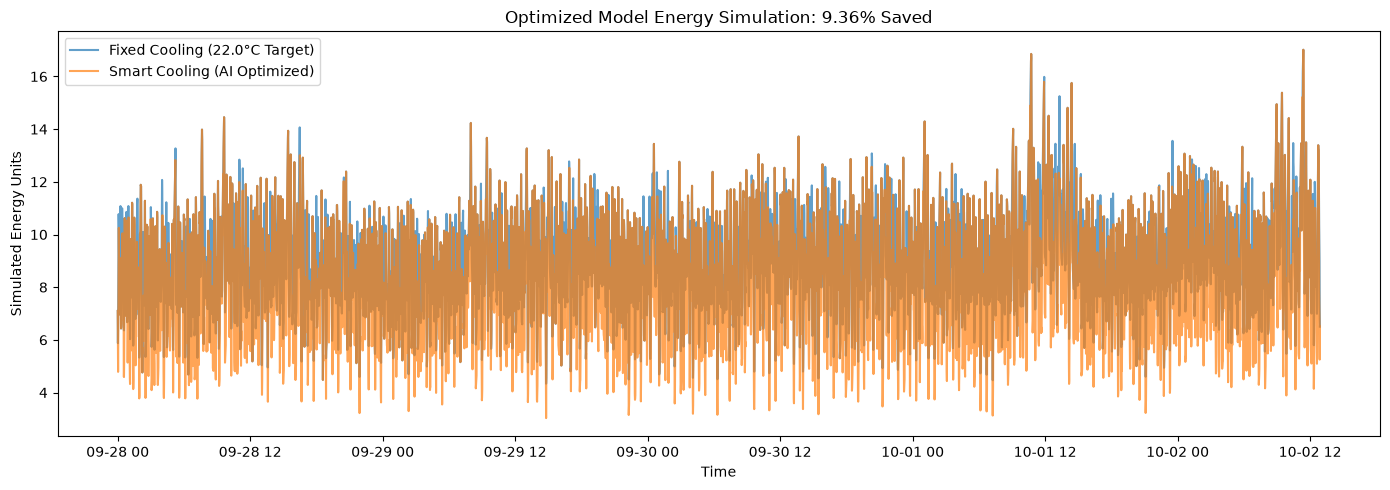

In [10]:

# 1. Prepare results using the optimized model predictions
results = pd.DataFrame({
    'time': test['time'].values,
    'current_temp': test['temp'].values,
    'actual_temp': y_test.values,
    'predicted_temp': optimized_test_predictions
})

# 2. Define simulation parameters
base_fan_power = 1.5

baseline_energy_list = []
smart_energy_list = []
target_list = []

# 3. Simulate baseline and smart cooling
for i in range(len(results)):

    actual = results['actual_temp'].iloc[i]
    predicted = results['predicted_temp'].iloc[i]
    current_temperature = results['current_temp'].iloc[i]

    # Baseline: fixed cooling target of 22.0°C
    diff_base = max(0.0, actual - 22.0)
    baseline_energy = base_fan_power + (diff_base ** 2) * 0.8
    baseline_energy_list.append(baseline_energy)

    # Smart controller: decide using current temperature and prediction
    if predicted < current_temperature:
        current_target = 22.5
    else:
        current_target = 22.0

    target_list.append(current_target)

    # Evaluate simulated energy using future actual temperature
    diff_smart = max(0.0, actual - current_target)
    smart_energy = base_fan_power + (diff_smart ** 2) * 0.8
    smart_energy_list.append(smart_energy)

# 4. Store simulation results
results['baseline_energy'] = baseline_energy_list
results['smart_energy'] = smart_energy_list
results['cooling_target'] = target_list

# 5. Calculate total simulated energy savings
baseline_total = sum(baseline_energy_list)
smart_total = sum(smart_energy_list)

savings = (
    (baseline_total - smart_total) / baseline_total
) * 100

print(f"Simulated Energy Saved: {savings:.2f}%")

# 6. Analyze controller behavior
relaxed_minutes = sum(target == 22.5 for target in target_list)
total_minutes = len(target_list)

relaxed_percentage = relaxed_minutes / total_minutes * 100

print("\n--- Controller Behavior ---")
print(f"Relaxed target minutes: {relaxed_minutes}")
print(f"Total simulation minutes: {total_minutes}")
print(f"Relaxed target percentage: {relaxed_percentage:.2f}%")
print(f"Strict target percentage: {100 - relaxed_percentage:.2f}%")

# 7. Plot energy comparison
plt.figure(figsize=(14, 5))

plt.plot(
    results['time'],
    results['baseline_energy'],
    label='Fixed Cooling (22.0°C Target)',
    alpha=0.7
)

plt.plot(
    results['time'],
    results['smart_energy'],
    label='Smart Cooling (AI Optimized)',
    alpha=0.7
)

plt.title(f'Optimized Model Energy Simulation: {savings:.2f}% Saved')
plt.ylabel('Simulated Energy Units')
plt.xlabel('Time')
plt.legend()
plt.tight_layout()

plt.savefig(
    r"D:\Projects\datacenter-efficiencyDMP\reports\figures\08_optuna_energy_simulation.png",
    dpi=150
)

plt.show()


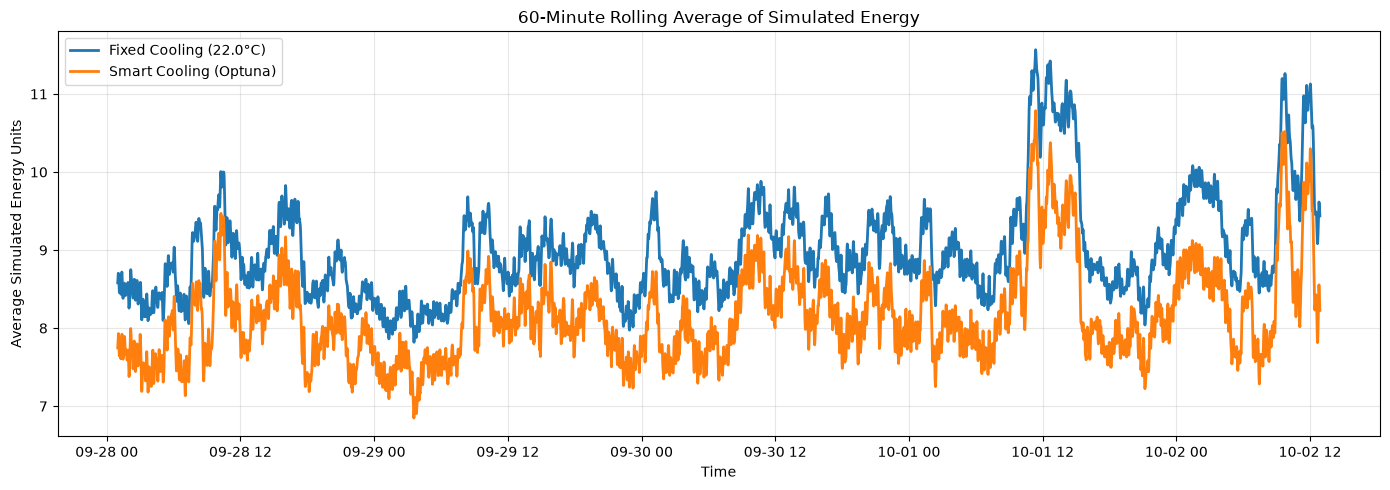

In [11]:

# Calculate 60-minute rolling averages
results['baseline_energy_smooth'] = (
    results['baseline_energy'].rolling(window=60).mean()
)

results['smart_energy_smooth'] = (
    results['smart_energy'].rolling(window=60).mean()
)

# Plot smoothed energy consumption
plt.figure(figsize=(14, 5))

plt.plot(
    results['time'],
    results['baseline_energy_smooth'],
    label='Fixed Cooling (22.0°C)',
    linewidth=2
)

plt.plot(
    results['time'],
    results['smart_energy_smooth'],
    label='Smart Cooling (Optuna)',
    linewidth=2
)

plt.title('60-Minute Rolling Average of Simulated Energy')
plt.ylabel('Average Simulated Energy Units')
plt.xlabel('Time')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"D:\Projects\datacenter-efficiencyDMP\reports\figures\08_optuna_energy_simulation_smoothed.png",
    dpi=150
)

plt.show()
